# AI Project 1

## Spring & Summer of 2026
## Dr. Tanghatari

## Group 7
- Mohammad Amin Haghjoo - 403110585
- Pouya Astaraki - 403110477

# 1.1 Packages and dependencies

All packages we used are imported here

In [9]:
import numpy as np
import pandas as pd
from collections import Counter
from typing import List, Tuple
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


# 1.2 Dataset loading

The WIDSM dataset is loaded in this cell.

In [10]:
def load_wisdm(file_path: str) -> pd.DataFrame:
    """
    Load the WISDM activity recognition dataset from a text file.

    Handles:
      - Multiple data rows on a single line (separated by ';')
      - Lines ending with ',;' instead of just ';' (A dataset format bug)
      - Empty lines and extra whitespace

    Parameters
    ----------
    file_path : str
        Path to the .txt file.

    Returns
    -------
    pd.DataFrame
        DataFrame with columns:
        ['userID', 'activityLabel', 'timestamp', 'ax', 'ay', 'az']
        - userID       : int
        - activityLabel: str
        - timestamp    : int (epoch time in milliseconds)
        - ax, ay, az   : float
    """
    records: List[Tuple] = []

    i: int = 0
    with open(file_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            # Split by semicolon to get individual records.
            # This handles both ';' and ',;' because the trailing comma will
            # be part of the last record string before the semicolon.
            parts = line.split(';')

            for part in parts:
                part = part.strip()
                if not part:
                    continue

                # Remove trailing commas (caused by ',;' endings)
                if part.endswith(','):
                    part = part[:-1]

                # Split by comma to get fields
                fields = part.split(',')

                # Expect exactly 6 fields
                if len(fields) != 6:
                    print(f"error at line: {i + 1}")
                    raise ValueError('WISDM activity recognition dataset must have 6 fields')


                user_id = int(fields[0].strip())
                activity = fields[1].strip()
                timestamp = int(fields[2].strip())
                ax = float(fields[3].strip())
                ay = float(fields[4].strip())
                az = float(fields[5].strip())
                anorm = (ax ** 2 + ay ** 2 + az ** 2) ** 0.5
                records.append((user_id, activity, timestamp, ax, ay, az, anorm))
                i = i + 1

    # Build DataFrame
    df = pd.DataFrame(
        records,
        columns=['userID', 'activityLabel', 'timestamp', 'ax', 'ay', 'az', 'anorm']
    )

    # Convert data types explicitly (Pandas will infer, but we enforce)
    df = df.astype({
        'userID': 'int64',
        'activityLabel': 'string',
        'timestamp': 'int64',
        'ax': 'float64',
        'ay': 'float64',
        'az': 'float64',
        'anorm': 'float64'
    })

    return df

df = load_wisdm('WISDM_ar_v1.1/WISDM_ar_v1.1_raw.txt')

print(df.info())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 1098208 entries, 0 to 1098207
Data columns (total 7 columns):
 #   Column         Non-Null Count    Dtype  
---  ------         --------------    -----  
 0   userID         1098208 non-null  int64  
 1   activityLabel  1098208 non-null  string 
 2   timestamp      1098208 non-null  int64  
 3   ax             1098208 non-null  float64
 4   ay             1098208 non-null  float64
 5   az             1098208 non-null  float64
 6   anorm          1098208 non-null  float64
dtypes: float64(4), int64(2), string(1)
memory usage: 58.7 MB
None
   userID activityLabel       timestamp        ax         ay        az  \
0      33       Jogging  49105962326000 -0.694638  12.680544  0.503953   
1      33       Jogging  49106062271000  5.012288  11.264028  0.953424   
2      33       Jogging  49106112167000  4.903325  10.882658 -0.081722   
3      33       Jogging  49106222305000 -0.612916  18.496431  3.023717   
4      33       Jogging  49106332290000 -1.18497

# 1.3 Deciding on the training/test split

As specified by the project spec, we will choose some users for training and others for testing. To do so, we will first look at how many entries belong to each user.

In [11]:
counts = df['userID'].value_counts().reindex(range(1, 37), fill_value=0).sort_index()

# Display the result
print("Entries per userID (1 to 36):")
print(counts)

# Optional: show total entries and number of unique users present
print(f"\nTotal entries: {len(df)}")
print(f"Unique userIDs in dataset: {df['userID'].nunique()}")

# Take user IDs 1 to 27 for training set.

Entries per userID (1 to 36):
userID
1     29978
2     23525
3     35161
4     11371
5     28510
6     29704
7     30967
8     41188
9     12923
10    34883
11    31658
12    32641
13    37093
14    38192
15    28155
16    20470
17    22020
18    32812
19    45383
20    56632
21    35436
22    22310
23    25673
24    25736
25    13468
26    32578
27    34959
28    21358
29    38245
30    25335
31    44282
32    35506
33    29453
34    35948
35    22394
36    32261
Name: count, dtype: int64

Total entries: 1098208
Unique userIDs in dataset: 36


# 1.4 Performing dataset split and sequence creation.

Users 1 to 27 are used for the training set.  (Approx. 74\% of the dataset.) Users 28 to 31 are used for the test set (Approx. 12\% of the dataset.), and 32 to 36 are used for the validation set. (Approx. 14\% of the dataset.)

In [12]:
def create_rnn_sequences(df: pd.DataFrame, T: int, training_cutoff=27, validation_cutoff=31) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Create sliding-window sequences for RNN training.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with columns ['userID', 'activityLabel', 'timestamp', 'ax', 'ay', 'az'].
    T : int
        Sequence length (number of time steps per sample).
    training_cutoff : int
        The cutoff point between training set/test set.
    validation_cutoff : int
        The cutoff point between validation set/test set.

    Returns
    -------
    X_train : np.ndarray, shape (n_samples_train, T, 4)
        Feature sequences (ax, ay, az) for each window.
    y_train : np.ndarray, shape (n_samples_train,)
        Majority-vote activity label for each sequence (strings).
    X_validation : np.ndarray, shape (n_samples_validation, T, 4)
        Feature sequences (ax, ay, az) for each window.
    y_validation : np.ndarray, shape (n_samples_validation,)
        Majority-vote activity label for each sequence (strings).
    X_test : np.ndarray, shape (n_samples_test, T, 4)
        Feature sequences (ax, ay, az) for each window.
    y_test : np.ndarray, shape (n_samples_test,)
        Majority-vote activity label for each sequence (strings).
    """
    X_list_train = []
    y_list_train = []

    X_list_test = []
    y_list_test = []

    X_list_validation = []
    y_list_validation = []

    # Group by user to keep sequences person‑specific
    for user_id, group in df.groupby('userID', sort=False):

        # Sort by time within each user
        group = group.sort_values('timestamp')

        # Extract features and labels as numpy arrays
        features = group[['ax', 'ay', 'az', 'anorm']].values  # shape (n_rows, 4)
        labels = group['activityLabel'].values       # shape (n_rows,)

        n_rows = len(features)
        if n_rows < T:
            # Not enough data for a single sequence – skip this user
            continue

        # Slide a window of length T with step size 1
        for start in range(n_rows - T + 1):
            end = start + T
            seq_X = features[start:end]  # shape (T, 4)

            # Majority vote for the label
            seq_labels = labels[start:end]
            # Counter.most_common(1) returns [(label, count)] – if tie, it picks the one
            # that appears first in the original order among the tied labels.
            majority_label = Counter(seq_labels).most_common(1)[0][0]

            if user_id <= training_cutoff:
                X_list_train.append(seq_X)
                y_list_train.append(majority_label)
            elif user_id <= validation_cutoff:
                X_list_test.append(seq_X)
                y_list_test.append(majority_label)
            else:
                X_list_validation.append(seq_X)
                y_list_validation.append(majority_label)


    X_train = np.array(X_list_train, dtype=np.float32)
    y_train = np.array(y_list_train, dtype=object)  # keep as strings

    X_validation = np.array(X_list_validation, dtype=np.float32)
    y_validation = np.array(y_list_validation, dtype=object)

    X_test = np.array(X_list_test, dtype=np.float32)
    y_test = np.array(y_list_test, dtype=object)


    return X_train, y_train, X_validation, y_validation, X_test, y_test


def enumerate_y_labels(y: np.ndarray) -> np.ndarray:
    y_enum = []
    for label in y:
        if label == "Walking":
            y_enum.append(1)
        elif label == "Jogging":
            y_enum.append(2)
        elif label == "Upstairs":
            y_enum.append(3)
        elif label == "Downstairs":
            y_enum.append(4)
        elif label == "Sitting":
            y_enum.append(5)
        elif label == "Standing":
            y_enum.append(0)
        else:
            raise ValueError("Invalid label")

    return np.asarray(y_enum)

# 1.6 Normalizing the dataset

For each sequence entry and all sequences, the mean and standard deviation are calculated and the acceleration components are normalized.

$$ \mathbf{a_{\text{norm}}} = (\frac{a_x - \mu_x}{\sigma_x}, \frac{a_y - \mu_y}{\sigma_y}, \frac{a_z - \mu_z}{\sigma_z}) $$

In [13]:
def normalize_components(X_train: np.ndarray, X_validation: np.ndarray, X_test: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Normalize each acceleration component (axis) by subtracting the global mean
    and dividing by the global standard deviation.

    The statistics (mean, std) are computed over all time steps and all samples
    pooled together, independently for each of the 4 axes.

    Parameters
    ----------
    X : np.ndarray, shape (n_samples, T, 4)
        Input acceleration sequences.

    Returns
    -------
    X_norm : np.ndarray, shape (n_samples, T, 4)
        Normalized sequences with the same shape.
    """
    # Flatten to (n_samples * T, 4) to compute global per‑axis statistics
    original_shape_train = X_train.shape
    original_shape_validation = X_validation.shape
    original_shape_test = X_test.shape

    X_flat_train = X_train.reshape(-1, 4)   # shape: (N*T, 4)
    X_flat_validation = X_validation.reshape(-1, 4)
    X_flat_test = X_test.reshape(-1, 4)
    # Compute mean and std for each axis

    mean = np.mean(X_flat_train, axis=0)   # shape: (4,)
    std = np.std(X_flat_train, axis=0)     # shape: (4,)


    # Safeguard: if an axis has zero variance, avoid division by zero.
    # Since (x - mean) will be 0 for all values, setting std to 1 keeps the result 0.
    std = np.where(std == 0, 1.0, std)

    # Normalize and reshape back
    X_norm_flat_train = (X_flat_train - mean) / std
    X_norm_train = X_norm_flat_train.reshape(original_shape_train)

    X_norm_flat_validation = (X_flat_validation - mean) / std
    X_norm_validation = X_norm_flat_validation.reshape(original_shape_validation)

    X_norm_flat_test = (X_flat_test - mean) / std
    X_norm_test = X_norm_flat_test.reshape(original_shape_test)

    return X_norm_train, X_norm_validation, X_norm_test

# 2.1 RNN from scratch

We have implemented a RNN class with adjustable parameters to be used and trained.

In [14]:
class RNN_scratch:

    def __init__(self, hidden_size: int, input_size=4, output_size=6):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.hs = []
        self.dropout_masks = []
        self.probs = None
        self.h_T = None

        self.d_W_xh = None
        self.d_W_hh = None
        self.d_W_hy = None
        self.d_b_h = None
        self.d_b_y = None

        # He initialization
        self.W_xh = np.random.randn(self.input_size, self.hidden_size) * np.sqrt(2 / self.input_size)
        self.W_hh = np.random.randn(self.hidden_size, self.hidden_size) * np.sqrt(2 / self.hidden_size)
        self.W_hy = np.random.randn(self.hidden_size, self.output_size) * np.sqrt(2 / self.hidden_size)
        self.b_h = np.zeros((1, self.hidden_size))
        self.b_y = np.zeros((1, self.output_size))

    def forward(self, X: np.ndarray, y_true: np.ndarray, keep_prob: float = 1.0) -> Tuple[np.ndarray, np.float64]:
        """
        Forward propagation for the RNN model.
        :param X: A numpy 3D array of shape (batch_size, T, 4)
        :param y_true: The correct label of the input sequences, shape (batch_size,) containing the correct index.
        :return: Returns a numpy 2D array of shape (batch_size, output_size) which are the output probabilities of the RNN model.
        """
        y_true = y_true.flatten()
        self.hs = []
        self.dropout_masks = []
        batch_size, T, _ = X.shape

        h = np.zeros((batch_size, self.hidden_size)) # h_0 = 0

        for t in range(T):
            X_t = X[:, t, :]
            h = np.tanh(
                X_t @ self.W_xh + h @ self.W_hh + self.b_h
            )

            if keep_prob < 1.0:
                mask = np.random.binomial(1, keep_prob, size=h.shape) / keep_prob
                self.dropout_masks.append(mask)
                h = h * mask
            else:
                self.dropout_masks.append(None)

            self.hs.append(h)
        self.h_T = h
        logits = h @ self.W_hy + self.b_y
        max_vals = np.max(logits, axis=1, keepdims=True)  # (B, 1)
        exp_logits = np.exp(logits - max_vals)            # (B, C)
        self.probs = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)

        # Select the probability of the true class for each sample
        # Using advanced indexing: probs[range(B), y_true]
        correct_probs = self.probs[np.arange(batch_size), y_true]
        # Add a tiny epsilon to avoid log(0)
        eps = 1e-15
        loss = -np.mean(np.log(correct_probs + eps))
        return self.probs, loss

    def backward(self, X: np.ndarray, y_true: np.ndarray, clip_norm: float = None, clip_value: float = None):
        """
        Backward propagation for the RNN model.
        """
        y_true = y_true.flatten()
        batch_size, T, _ = X.shape

        y_one_hot = np.zeros((batch_size, self.output_size))
        y_one_hot[np.arange(batch_size), y_true] = 1.0

        d_logits = self.probs - y_one_hot
        d_W_hy = (self.h_T.T @ d_logits) / batch_size
        d_b_y = np.sum(d_logits, axis=0, keepdims=True) / batch_size

        d_W_hh = np.zeros_like(self.W_hh)
        d_W_xh = np.zeros_like(self.W_xh)
        d_b_h = np.zeros_like(self.b_h)

        d_h = d_logits @ self.W_hy.T
        d_z = np.zeros_like(d_h)
        for t in reversed(range(T)):

            if self.dropout_masks[t] is not None:
                d_h = d_h * self.dropout_masks[t]

            d_z = d_h * (1.0 - self.hs[t] ** 2)
            d_h = d_z @ self.W_hh.T

            d_W_xh += X[:, t, :].T @ d_z / batch_size

            if t == 0:
                h_last = np.zeros_like(d_h)
            else:
                h_last = self.hs[t - 1]

            d_W_hh += h_last.T @ d_z / batch_size

            d_b_h += np.sum(d_z, axis=0, keepdims=True) / batch_size

        self.d_W_xh = d_W_xh
        self.d_W_hh = d_W_hh
        self.d_W_hy = d_W_hy
        self.d_b_h = d_b_h
        self.d_b_y = d_b_y

        self.clip_gradients(max_norm=clip_norm, max_value=clip_value)

    def clip_gradients(self, max_norm: float = None, max_value: float = None):
        """
        Clip gradients to prevent exploding gradients.

        Parameters
        ----------
        max_norm : float, optional
            If provided, scales all gradients so that their global L2 norm <= max_norm.
        max_value : float, optional
            If provided, clamps each gradient element to [-max_value, max_value].

        At least one of max_norm or max_value must be provided.
        """
        grads = [self.d_W_xh, self.d_W_hh, self.d_W_hy, self.d_b_h, self.d_b_y]

        # Global norm clipping (preserves direction)
        if max_norm is not None:
            # Compute total L2 norm of all gradients
            total_norm = 0.0
            for g in grads:
                if g is not None:
                    total_norm += np.sum(g ** 2)
            total_norm = np.sqrt(total_norm)

            # Scale if above threshold
            if total_norm > max_norm:
                scale = max_norm / (total_norm + 1e-8)  # add epsilon to avoid division by zero
                for g in grads:
                    if g is not None:
                        g *= scale

        # Value clipping (element-wise)
        if max_value is not None:
            for g in grads:
                if g is not None:
                    np.clip(g, -max_value, max_value, out=g)  # in-place clipping

    def train(self, learning_rate: float, batch_size: int, epochs: int, X_train: np.ndarray, y_train: np.ndarray, X_validation: np.ndarray, y_validation: np.ndarray, clip_norm: float = None, clip_value: float = None, drop_prob=0.0, l2=0.0) -> Tuple[list, list]:
        """
        Training the RNN using mini-batch gradient descent.

        Parameters
        ----------
        learning_rate : float
            Step size for weight updates.
        batch_size : int
            Number of sequences per batch.
        epochs : int
            Number of full passes over the dataset.
        X_train: np.ndarray, shape (N, T, 3)
            Full training dataset.
        y_train : np.ndarray, shape (N,)
            True integer labels for each sequence.
        clip_norm : float, optional
            Global norm clipping threshold.
        clip_value : float, optional
            Element-wise value clipping threshold.

        Returns
        -------
        epoch_losses_train : list
            Average training loss per epoch.
        epoch_losses_test: list
            Average test loss per ten epochs.
        """
        num_samples = X_train.shape[0]
        epoch_losses_train = []
        epoch_losses_validation = []
        keep_prob = 1.0 - drop_prob

        for epoch in range(epochs):
            total_loss = 0.0

            indices = np.arange(num_samples)
            np.random.shuffle(indices)

            for start in range(0, num_samples, batch_size):
                end = min(start + batch_size, num_samples)
                batch_indices = indices[start:end]

                X_batch = X_train[batch_indices]
                y_batch = y_train[batch_indices]

                probs, loss = self.forward(X_batch, y_batch, keep_prob=keep_prob)

                self.backward(X_batch, y_batch, clip_norm=clip_norm, clip_value=clip_value)

                self.W_xh -= learning_rate * (self.d_W_xh + l2 * self.W_xh)
                self.W_hh -= learning_rate * (self.d_W_hh + l2 * self.W_hh)
                self.W_hy -= learning_rate * (self.d_W_hy + l2 * self.W_hy)
                self.b_h -= learning_rate * (self.d_b_h + l2 * self.b_h)
                self.b_y -= learning_rate * (self.d_b_y + l2 * self.b_y)

                total_loss += loss * len(X_batch)

            avg_loss = total_loss / num_samples
            epoch_losses_train.append(avg_loss)

            if (epoch + 1) % 10 == 0 or epoch == 0:
                print(f"Epoch {epoch+1}/{epochs}, Average Training Set Loss: {avg_loss:.6f}")
                _, loss_validation = self.forward(X_validation, y_validation, keep_prob=1.0)
                epoch_losses_validation.append(loss_validation)
                print(f"Epoch {epoch+1}/{epochs}, Average Validation Set Loss: {loss_validation:.6f}")

            if epoch > 50 and epoch % 30 == 0:
                learning_rate *= 0.5
                print(f"Epoch {epoch+1}: Reducing LR to {learning_rate:.6f}")

        return epoch_losses_train, epoch_losses_validation

    def save_model(self, filepath: str):
        """
        Save the current model parameters to a .npz file.
        Also stores the architecture: input_size, hidden_size, output_size.
        """
        np.savez_compressed(
            filepath,
            W_xh=self.W_xh,
            W_hh=self.W_hh,
            W_hy=self.W_hy,
            b_h=self.b_h,
            b_y=self.b_y,
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            output_size=self.output_size
        )
        print(f"Model saved to {filepath}")

    def load_model(self, filepath: str):
        """
        Load model parameters from a .npz file.
        The architecture parameters are checked against the current instance.
        """
        data = np.load(filepath)

        # Validate architecture (optional but recommended)
        if (data['input_size'] != self.input_size or
            data['hidden_size'] != self.hidden_size or
            data['output_size'] != self.output_size):
            raise ValueError(
                f"Architecture mismatch: saved model has "
                f"input={data['input_size']}, hidden={data['hidden_size']}, output={data['output_size']}, "
                f"but current RNN has input={self.input_size}, hidden={self.hidden_size}, output={self.output_size}."
            )

        # Load weights and biases
        self.W_xh = data['W_xh']
        self.W_hh = data['W_hh']
        self.W_hy = data['W_hy']
        self.b_h = data['b_h']
        self.b_y = data['b_y']

        print(f"Model loaded from {filepath}")

In [18]:
T = 25
lr = 0.001
batch_size = 64
epochs = 200
clip_value = None
clip_norm = 5
hidden_neurons = 48
drop_rate = 0.15
l2 = 0.0002

X_train, y_train, X_validation, y_validation, X_test, y_test = create_rnn_sequences(df, T=T)

y_train = enumerate_y_labels(y_train)
y_validation = enumerate_y_labels(y_validation)
y_test = enumerate_y_labels(y_test)

X_train, X_validation, X_test = normalize_components(X_train=X_train, X_validation=X_validation, X_test=X_test)

rnn = RNN_scratch(hidden_size=hidden_neurons, input_size=4)
rnn.load_model("rnn_weights_2.npz")

rnn.train(learning_rate=lr, batch_size=batch_size, epochs=epochs, X_train=X_train, y_train=y_train, X_validation=X_validation, y_validation=y_validation, clip_value=clip_value, clip_norm=clip_norm, drop_prob=drop_rate, l2=l2)


Model loaded from rnn_weights_2.npz
Epoch 1/200, Average Training Set Loss: 0.479571
Epoch 1/200, Average Validation Set Loss: 0.517338
Epoch 10/200, Average Training Set Loss: 0.470257
Epoch 10/200, Average Validation Set Loss: 0.504405


KeyboardInterrupt: 

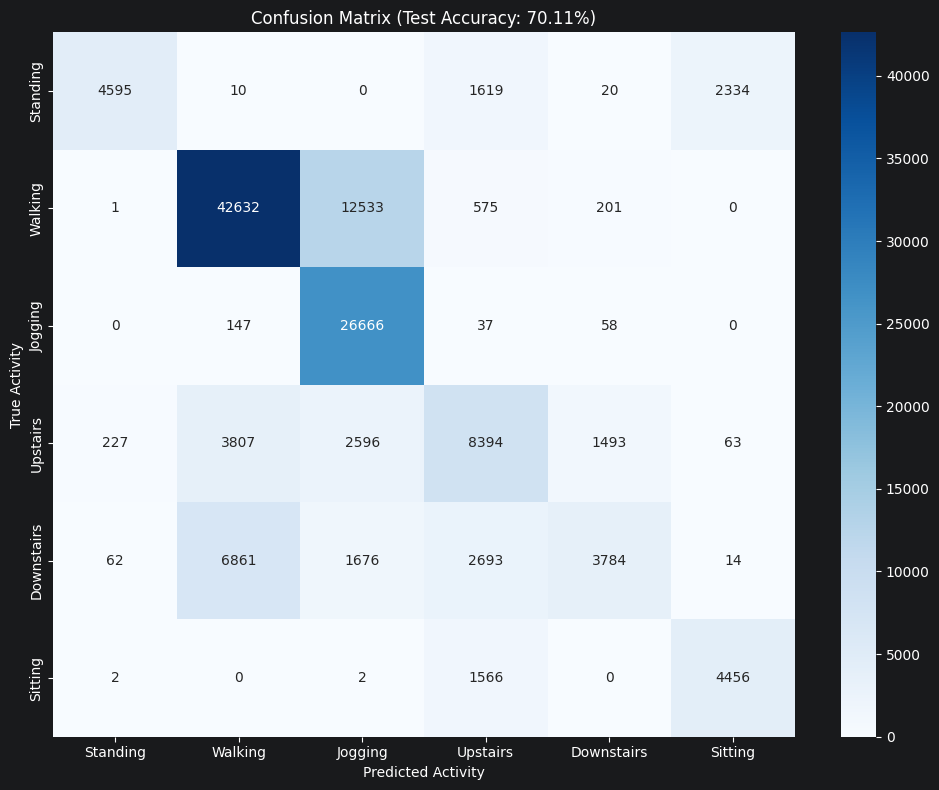

In [19]:
def predict_batches(rnn, X, y, batch_size=256):
    """
    Run the RNN in forward mode over the entire dataset in batches
    to collect predicted class indices.
    """
    num_samples = X.shape[0]
    all_preds = []

    for start in range(0, num_samples, batch_size):
        end = min(start + batch_size, num_samples)
        X_batch = X[start:end]
        y_batch = y[start:end]  # needed for forward() signature

        # Forward pass (we ignore the loss)
        probs, _ = rnn.forward(X_batch, y_batch)

        # Get the predicted class (argmax over output probabilities)
        preds = np.argmax(probs, axis=1)
        all_preds.append(preds)

    return np.concatenate(all_preds)

# ======== 1. Get predictions ========
y_pred = predict_batches(rnn, X_test, y_test, batch_size=256)

# ======== 2. Compute confusion matrix ========
# WISDM typical label order (if you used LabelEncoder on ['Walking','Jogging','Upstairs','Downstairs','Sitting','Standing'])
# If you used a different mapping, adjust the labels list accordingly.
activity_labels = ['Standing', 'Walking', 'Jogging', 'Upstairs', 'Downstairs', 'Sitting']

cm = confusion_matrix(y_test, y_pred)

# ======== 3. Plot the confusion matrix ========
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=activity_labels, yticklabels=activity_labels)
plt.xlabel('Predicted Activity')
plt.ylabel('True Activity')
plt.title(f'Confusion Matrix (Test Accuracy: {np.mean(y_pred == y_test):.2%})')
plt.tight_layout()
plt.show()

np.savez_compressed(
            "rnn_weights_2.npz",
            W_xh=rnn.W_xh,
            W_hh=rnn.W_hh,
            W_hy=rnn.W_hy,
            b_h=rnn.b_h,
            b_y=rnn.b_y,
            input_size=rnn.input_size,
            hidden_size=rnn.hidden_size,
            output_size=rnn.output_size
        )